In [1]:
import torch
import torch.nn as nn
#from torchtyping import TensorType

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [3]:
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
#Load MNIST handwritten digits
from torchvision import datasets, transforms
dataset = datasets.MNIST('data', download=True, transform=transforms.ToTensor())

100%|██████████| 9.91M/9.91M [00:17<00:00, 577kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 104kB/s]
100%|██████████| 1.65M/1.65M [00:02<00:00, 667kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 15.2MB/s]


In [5]:
# Create the train and test dataloader from the MNIST dataset
train_dataloader = torch.utils.data.DataLoader(dataset, batch_size=64, shuffle=True)
test_dataloader = torch.utils.data.DataLoader(dataset, batch_size=64, shuffle=False)

In [6]:
class DigitRecognizer(nn.Module):
    def __init__(self):
        super().__init__()
        torch.manual_seed(0)
        # Architecture: Linear(784, 512) -> ReLU -> Dropout(0.2) -> Linear(512, 10
        self.first_layer = nn.Linear(784,512) # (in_features, out_features)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=0.2)
        self.last_layer = nn.Linear(512, 10)

    def forward(self, images):
        # Return raw logits for CrossEntropyLoss
        return self.last_layer(self.dropout(self.relu(self.first_layer(images))))

In [7]:
model = DigitRecognizer().to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters())

In [8]:
epochs = 5
for epoch in range(epochs):
  for images, labels in train_dataloader:
    images = images.view(images.shape[0], 784).to(device)
    labels = labels.to(device)

    # TRAINING BODY
    model_prediction = model(images)
    optimizer.zero_grad()
    loss = loss_function(model_prediction, labels)
    loss.backward()
    optimizer.step()

In [9]:
# Verify that both the model and a sample data tensor are on the GPU (CUDA)
model_device = next(model.parameters()).device
print(f"Model is on device: {model_device}")

sample_batch, _ = next(iter(train_dataloader))
sample_batch_device = sample_batch.to(device).device
print(f"Data tensor is on device: {sample_batch_device}")

# This assertion will pass successfully if you are using the GPU
assert 'cuda' in str(model_device) and 'cuda' in str(sample_batch_device), "Not running on GPU!"

Model is on device: cuda:0
Data tensor is on device: cuda:0


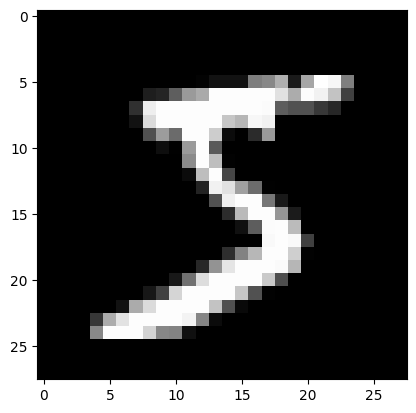

Predicted: 5 | Label: 5


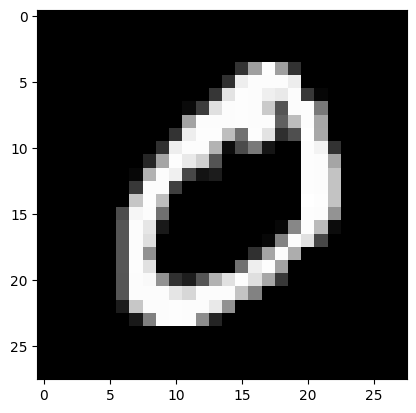

Predicted: 0 | Label: 0


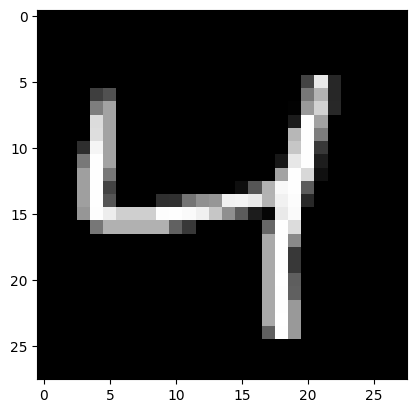

Predicted: 4 | Label: 4


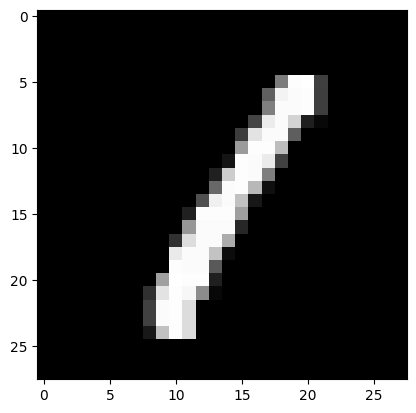

Predicted: 1 | Label: 1


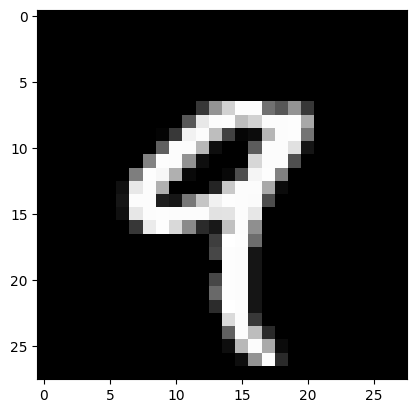

Predicted: 9 | Label: 9


In [10]:
model.eval()
with torch.no_grad():
    for images, labels in test_dataloader:
        # Ensure we move validation images to the same device
        images_flat = images.view(images.shape[0], 784).to(device)

        model_prediction = model(images_flat)
        # The prediction class is the index with the maximum logit value
        _, idx = torch.max(model_prediction, dim=1)

        for i in range(min(5, len(images))): # limit display to first 5 items for clean output
            plt.imshow(images[i].view(28, 28), cmap='gray')
            plt.show()
            print(f"Predicted: {idx[i].item()} | Label: {labels[i].item()}")
        break

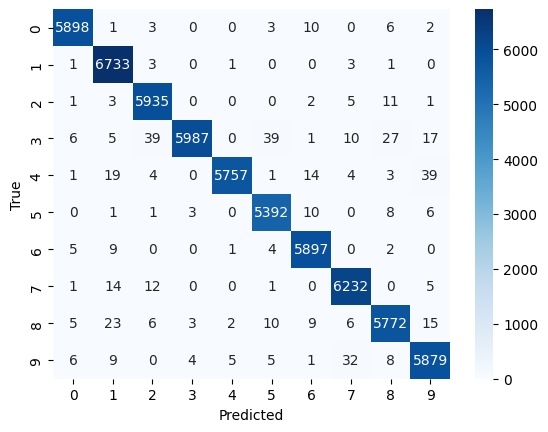

In [11]:
# Create the confusion matrix for this
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_true = []
y_pred = []
with torch.no_grad():
    for images, labels in test_dataloader:
        images_flat = images.view(images.shape[0], 784).to(device)
        model_prediction = model(images_flat)
        _, idx = torch.max(model_prediction, dim=1)
        y_true.extend(labels.tolist())
        y_pred.extend(idx.tolist())

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

In [ ]:
# Calcualte the accuracy % of the model
accuracy = (cm.diagonal().sum() / cm.sum()) * 100
print(f"Accuracy: {accuracy:.2f}%")

Accuracy: 99.11%
